# Inspect the Caltech P-phase archive

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
if not (root / "src/data.py").exists():
    raise RuntimeError("Launch Jupyter from the repository or notebooks folder.")
sys.path.insert(0, str(root))
from src.data import ROOT, LEVELS, load, mix

The included inventory was generated by opening all HDF5 events. Inspect the two array geometries and one untrimmed aperture from the release.

In [2]:
inventory = pd.read_csv(ROOT / "data/prepared/inventory.csv")
display(inventory.groupby(["array", "rows", "samples", "dt_s"]).size().rename("events"))

array       rows  samples  dt_s
longvalley  4670  200      0.01    151
ridgecrest  4718  200      0.01     30
Name: events, dtype: int64

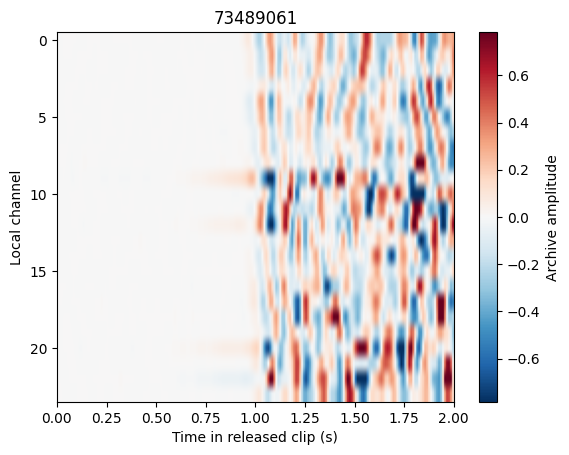

In [3]:
import matplotlib.pyplot as plt

events, pairs = load(ROOT / "data/prepared")
i = 0
g = pairs["raw"][i]
v = np.quantile(abs(g), 0.99)
plt.imshow(g, aspect="auto", extent=(0, 2, 23.5, -0.5), cmap="RdBu_r", vmin=-v, vmax=v)
plt.title(str(events.iloc[i].event_id))
plt.xlabel("Time in released clip (s)")
plt.ylabel("Local channel")
plt.colorbar(label="Archive amplitude")
plt.show()